<a href="https://colab.research.google.com/github/saikiran-shriram/ml-notebooks/blob/main/Multi_Variable_Linear_Regression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# ---- Sample multi-feature dataset ----
# Features: [size_sqft, num_bedrooms, age_years]
X = np.array([
    [2104, 5, 45],
    [1416, 3, 40],
    [1534, 3, 30],
    [852,  2, 36],
    [1940, 4, 22]
], dtype=float)

y = np.array([460, 232, 315, 178, 400], dtype=float)


In [2]:
# ---- Feature scaling: z-score normalization ----
mu = np.mean(X, axis=0)
sigma = np.std(X, axis=0)
X_norm = (X - mu) / sigma

m, n = X_norm.shape  # m = examples, n = features


In [3]:
# ---- Initialize parameters ----
w = np.zeros(n)
b = 0.0

In [4]:
# ---- Prediction function (vectorized) ----
def predict(X, w, b):
    return np.dot(X, w) + b

In [5]:
# ---- Cost function ----
def compute_cost(X, y, w, b):
    m = X.shape[0]
    predictions = predict(X, w, b)
    cost = (1 / (2 * m)) * np.sum((predictions - y) ** 2)
    return cost

In [6]:
# ---- Gradient computation ----
def compute_gradient(X, y, w, b):
    m = X.shape[0]
    predictions = predict(X, w, b)
    error = predictions - y
    dj_dw = (1 / m) * np.dot(X.T, error)
    dj_db = (1 / m) * np.sum(error)
    return dj_dw, dj_db

In [7]:
# ---- Gradient descent ----
def gradient_descent(X, y, w, b, learning_rate, iterations):
    cost_history = []
    for i in range(iterations):
        dj_dw, dj_db = compute_gradient(X, y, w, b)
        w = w - learning_rate * dj_dw
        b = b - learning_rate * dj_db
        cost = compute_cost(X, y, w, b)
        cost_history.append(cost)
        if i % 100 == 0:
            print(f"Iteration {i}: Cost {cost:.4f}")
    return w, b, cost_history

In [8]:
# ---- Run training ----
w_final, b_final, cost_history = gradient_descent(
    X_norm, y, w, b, learning_rate=0.1, iterations=1000
)

print("\nFinal weights:", w_final)
print("Final bias:", b_final)

Iteration 0: Cost 44281.5584
Iteration 100: Cost 226.8153
Iteration 200: Cost 216.4050
Iteration 300: Cost 208.3629
Iteration 400: Cost 202.1502
Iteration 500: Cost 197.3508
Iteration 600: Cost 193.6433
Iteration 700: Cost 190.7791
Iteration 800: Cost 188.5665
Iteration 900: Cost 186.8572

Final weights: [  4.43093253  98.66966426 -21.30181678]
Final bias: 316.9999999999998


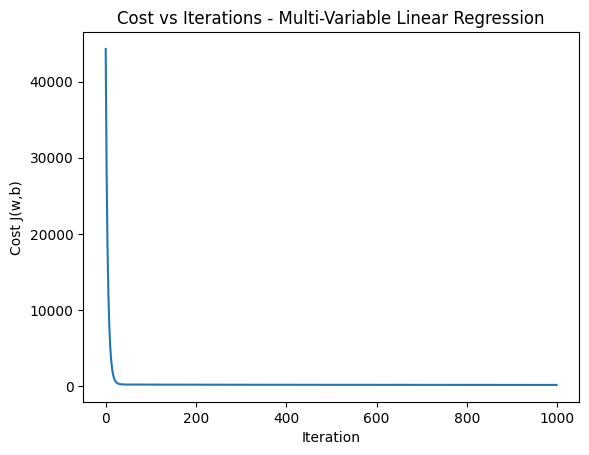

In [9]:
# ---- Plot cost convergence ----
plt.plot(cost_history)
plt.xlabel("Iteration")
plt.ylabel("Cost J(w,b)")
plt.title("Cost vs Iterations - Multi-Variable Linear Regression")
plt.show()

In [10]:
# ---- Test a prediction ----
test_house = np.array([1600, 3, 25])
test_house_norm = (test_house - mu) / sigma
predicted_price = predict(test_house_norm, w_final, b_final)
print(f"\nPredicted price for {test_house}: {predicted_price:.2f}")


Predicted price for [1600    3   25]: 304.20
